# Freight rate prediction

EDA, validation setup and model comparison. The final model lives in `model.py`, this notebook is how I got there.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from model import prep, good_labels, lin_X, fit, predict, GBM_COLS

pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams['figure.figsize'] = (11, 3.5)

df = pd.read_csv('data/train_test.csv', parse_dates=['date'])
val = pd.read_csv('data/validation.csv', parse_dates=['date'])
dec = pd.read_csv('data/december_chart_inputs.csv')
print(df.shape, val.shape, dec.shape)
print('train', df.date.min().date(), df.date.max().date(), '| val', val.date.min().date(), val.date.max().date())
df.head(3)

(48000, 14) (12000, 13) (31, 7)
train 2025-01-01 2025-10-31 | val 2025-11-01 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.091,-76.789,38.169,-72.746,274.300,Dry Van,30658.000,2025-01-01,0.957,2.396,645.410
1,TR-000002,Richmond,Philadelphia,38.091,-76.789,39.223,-72.967,280.500,Reefer,17555.000,2025-01-01,0.976,2.434,679.970
2,TR-000003,Philadelphia,Green Bay,39.223,-72.967,44.303,-87.529,967.800,Dry Van,31721.000,2025-01-01,1.010,1.845,1802.540


## 1. First look

Train is Jan-Oct, validation is Nov-Dec, so this is a forecasting problem and a random split would be the wrong test.
The December chart file only has pickup, delivery, distance, equipment, weight and date.

In [2]:
print('duplicate ids:', df.load_id.duplicated().sum(), val.load_id.duplicated().sum())
print(pd.concat([df.isna().sum(), val.isna().sum()], axis=1, keys=['train', 'val']).query('train > 0').astype(int))
df.describe().T[['min', '50%', 'max']]

duplicate ids: 0 0
              train  val
weight          300  165
market_index    374  249


,min,50%,max
pickup_lat,28.358,35.295,44.303
pickup_lon,-121.698,-88.089,-69.500
delivery_lat,28.358,35.295,44.303
delivery_lon,-121.698,-87.529,-69.500
distance,70.000,953.300,3439.800
weight,-47500.000,31436.500,47500.000
date,2025-01-01 00:00:00,2025-05-31 00:00:00,2025-10-31 00:00:00
market_index,0.676,1.056,1.468
quote_signal,0.692,2.056,3.610
posted_rate,57.220,2030.760,25533.000


## 2. Data problems

**Weight** has negative and missing values. The negatives have the same distribution as the positives, so they are sign flips and I take `abs()`.

train negative 0.61%  missing 0.62%
val negative 1.21%  missing 1.38%


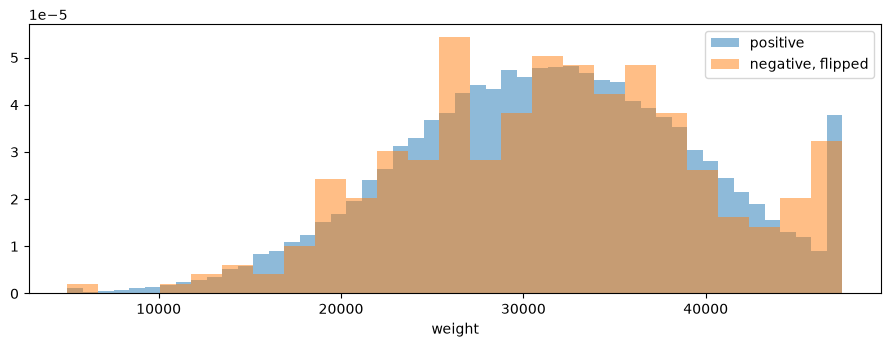

In [3]:
for name, d in [('train', df), ('val', val)]:
    print(name, 'negative %.2f%%' % (100 * (d.weight < 0).mean()), ' missing %.2f%%' % (100 * d.weight.isna().mean()))
plt.hist(df.weight[df.weight > 0], bins=50, density=True, alpha=.5, label='positive')
plt.hist(-df.weight[df.weight < 0], bins=25, density=True, alpha=.5, label='negative, flipped')
plt.legend(); plt.xlabel('weight'); plt.show()

**Target.** Rate per mile should sit in a narrow band. It mostly does, but there are two clusters far away from it.

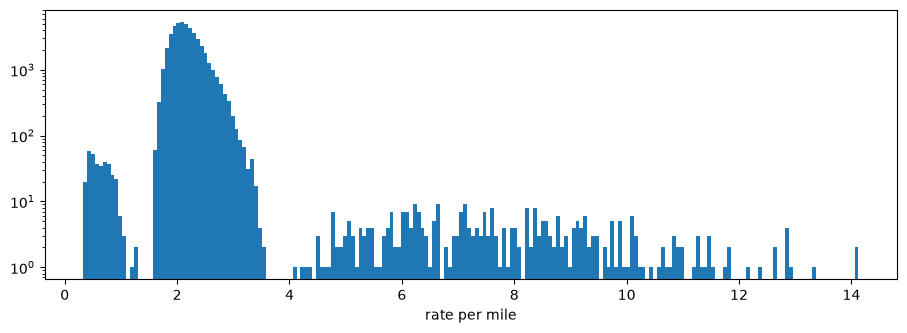

rpm < 1.5: 337  rpm > 4: 340  share: 1.41%
normal range: 1.58 - 3.57


In [4]:
df['rpm'] = df.posted_rate / df.distance
plt.hist(df.rpm, bins=200); plt.yscale('log'); plt.xlabel('rate per mile'); plt.show()
print('rpm < 1.5:', (df.rpm < 1.5).sum(), ' rpm > 4:', (df.rpm > 4).sum(), ' share: %.2f%%' % (100 * ((df.rpm < 1.5) | (df.rpm > 4)).mean()))
print('normal range:', df.rpm[df.rpm.between(1.5, 4)].min().round(2), '-', df.rpm[df.rpm.between(1.5, 4)].max().round(2))

About 1.4% of the rates are roughly 3-5x too low or too high. Nothing in the features explains them, so they are bad labels and I drop them from training (`good_labels` keeps 1.5 < rpm < 4). All scores below are on the clean rows.

**New cities.** Validation has cities that never appear in training.

In [5]:
new = set(val.pickup) - set(df.pickup)
print(sorted(new))
print('val rows touching a new city: %.1f%%' % (100 * (val.pickup.isin(new) | val.delivery.isin(new)).mean()))
print('each city has one lat/lon:', df.groupby('pickup')[['pickup_lat', 'pickup_lon']].nunique().max().tolist())

['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
val rows touching a new city: 12.1%
each city has one lat/lon: [1, 1]


So city names are no use for 12% of validation. Coordinates are available for every city, so the model gets lat/lon instead.

**market_index** is basically one value per day (plus a little noise) with a weekly cycle. Missing values can be filled from the same day. Validation stays inside the range seen in training.

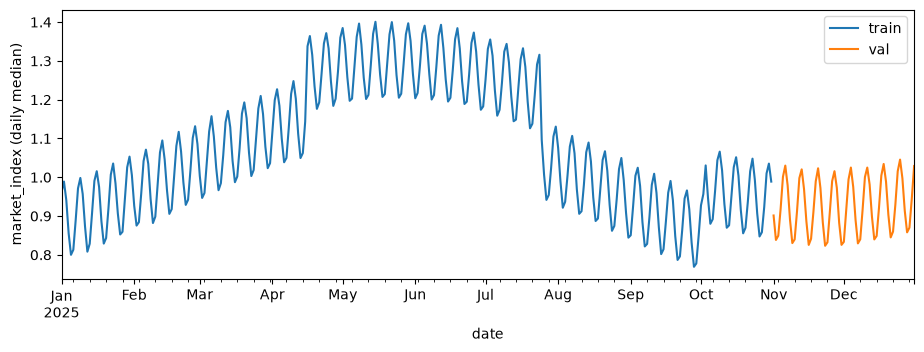

std within a day 0.025, between days 0.167


In [6]:
df.groupby('date').market_index.median().plot(label='train')
val.groupby('date').market_index.median().plot(label='val')
plt.legend(); plt.ylabel('market_index (daily median)'); plt.show()
print('std within a day %.3f, between days %.3f' % (df.groupby('date').market_index.std().mean(), df.groupby('date').market_index.median().std()))

## 3. quote_signal

On the first rows it looks like rate per mile, which would make it the best feature by far. Checking that day by day:

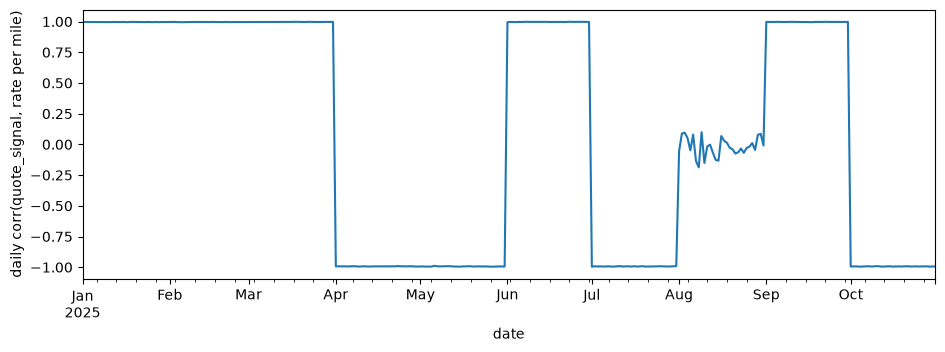

In [7]:
ok = good_labels(df)
ok.groupby('date')[['quote_signal', 'rpm']].corr().unstack().iloc[:, 1].plot()
plt.ylabel('daily corr(quote_signal, rate per mile)'); plt.show()

It is +1 in some months, -1 in others and ~0 in August. So it is only useful if you know which month you are in, and Nov/Dec are not in the training data.

I can't compute that correlation for validation (no labels), but rate per mile drops with distance, so the correlation between quote_signal and distance tells the same story without labels:

In [8]:
for name, d in [('train', df), ('val', val)]:
    print(name, d.groupby(d.date.dt.month).apply(lambda g: g.quote_signal.corr(np.log(g.distance))).round(2).to_dict())

train {1: -0.82, 2: -0.82, 3: -0.79, 4: 0.81, 5: 0.82, 6: -0.8, 7: 0.81, 8: 0.02, 9: -0.8, 10: 0.82}
val {11: 0.01, 12: 0.01}


In validation it is ~0 in both months, same as August. So quote_signal carries nothing there and I leave it out. Section 6 checks this with numbers.

## 4. Time effects

Fit a simple linear model on log(rate) (distance, weight, equipment, market index, trend) and look at what is left over by day.

trend: 8.0% per year


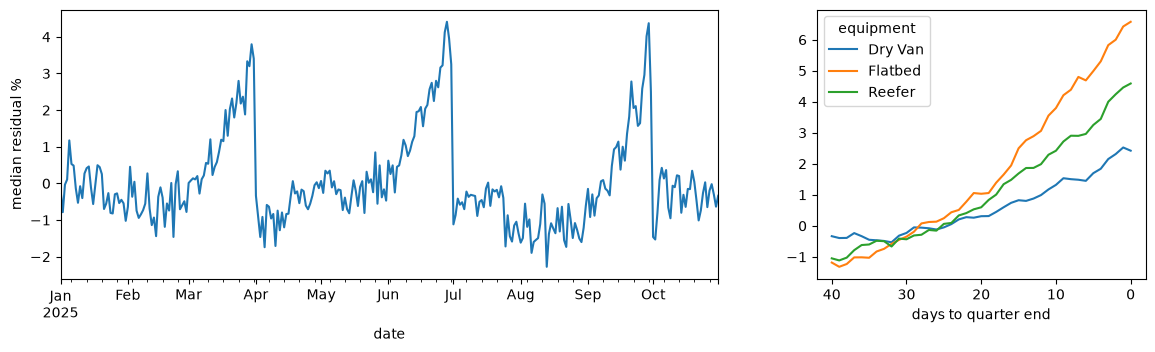

In [9]:
d = good_labels(prep(df))
X = lin_X(d.assign(days_to_qend=99), d.weight.median())   # 99 switches the ramp term off
lr = LinearRegression().fit(X, np.log(d.posted_rate))
d['res'] = np.log(d.posted_rate) - lr.predict(X)
print('trend: %.1f%% per year' % (100 * (np.exp(lr.coef_[list(X.columns).index('t')]) - 1)))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2, 1]})
(100 * d.groupby('date').res.median()).plot(ax=ax[0]); ax[0].set_ylabel('median residual %')
last = d[d.days_to_qend <= 40].groupby(['days_to_qend', 'equipment'], observed=True).res.median().unstack()
(100 * last.rolling(5, center=True, min_periods=1).mean()).plot(ax=ax[1]); ax[1].invert_xaxis(); ax[1].set_xlabel('days to quarter end')
plt.show()

Two things:
- rates climb over the last ~30 days of every quarter and reset on day one of the next. Flatbed and reefer climb more than dry van. December is a quarter end, so half of validation sits in this ramp.
- there is a steady upward trend. A tree model can't extrapolate that into Nov-Dec.

So the plan is a linear part for the things that have to carry forward in time (trend, ramp, market index) and LightGBM on what is left.

## 5. Validation setup

Validation is the two months after training and has 8 unseen cities out of 72. Each fold copies both:
- train on everything before a date, test on the next block (May-Jun, Aug-Sep, Oct). The first two are the last two months of a quarter, like Nov-Dec.
- 7 of the 64 cities are removed from the training part of each fold, so the test block has real unseen-city rows.

In [10]:
folds = [('2025-05-01', '2025-06-30'), ('2025-08-01', '2025-09-30'), ('2025-10-01', '2025-10-31')]
full = prep(df)
full['month'] = full.date.dt.month
full['pickup_c'] = full.pickup.astype('category')
full['delivery_c'] = full.delivery.astype('category')

def cv(f, data=full, hide=7, clean=True):
    cities = np.random.default_rng(42).permutation(sorted(data.pickup.unique()))
    out = []
    for i, (a, b) in enumerate(folds):
        hidden = cities[i * hide:(i + 1) * hide]
        hid = data.pickup.isin(hidden) | data.delivery.isin(hidden)
        tr = data[(data.date < a) & ~hid]
        if clean:
            tr = good_labels(tr)
        te = good_labels(data[data.date.between(a, b)])
        err = f(tr, te) - te.posted_rate
        pct = 100 * err / te.posted_rate
        out.append({'fold': a[5:7] + '-' + b[5:7], 'mape': pct.abs().mean(), 'mae': err.abs().mean(),
                    'rmse': (err ** 2).mean() ** .5, 'mape_new_city': pct[hid[te.index]].abs().mean(), 'bias': pct.mean()})
    return pd.DataFrame(out).set_index('fold')

def final(tr, te):
    return predict(fit(tr), te)

def linear_only(tr, te):
    w = tr.weight.median()
    return np.exp(LinearRegression().fit(lin_X(tr, w), np.log(tr.posted_rate)).predict(lin_X(te, w)))

def gbm_only(cols):
    def f(tr, te):
        m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, random_state=42, verbose=-1)
        return np.exp(m.fit(tr[cols], np.log(tr.posted_rate)).predict(te[cols]))
    return f

def rpm_baseline(tr, te):
    rpm = (tr.posted_rate / tr.distance).groupby(tr.equipment, observed=True).median()
    return te.equipment.map(rpm).astype(float) * te.distance

cv(final)

,mape,mae,rmse,mape_new_city,bias
fold,,,,,
05-06,1.383,33.551,48.713,1.443,-0.262
08-09,1.484,34.339,49.821,1.630,0.783
10-10,1.538,36.526,53.005,1.666,-0.858


## 6. Model comparison

In [11]:
models = {'median rpm x distance': rpm_baseline, 'linear only': linear_only, 'lgbm only': gbm_only(GBM_COLS),
          'lgbm + time index': gbm_only(GBM_COLS + ['t']), 'linear + lgbm on residuals': final}
pd.DataFrame({k: cv(f).mean() for k, f in models.items()}).T

,mape,mae,rmse,mape_new_city,bias
median rpm x distance,8.568,177.150,249.822,9.390,-2.864
linear only,2.604,55.386,74.395,2.645,-0.166
lgbm only,3.575,84.622,110.468,3.561,-3.316
lgbm + time index,2.015,47.001,68.238,2.109,-1.155
linear + lgbm on residuals,1.468,34.805,50.513,1.580,-0.112


The combination is clearly best. LightGBM alone is bad on the later folds because it can't follow the trend, and the linear model alone misses the regional differences.

**Random split vs time split.** Same models, scored both ways:

In [12]:
def random_cv(f, data=full):
    data = good_labels(data)
    scores = []
    for a, b in KFold(5, shuffle=True, random_state=42).split(data):
        tr, te = data.iloc[a], data.iloc[b]
        scores.append(100 * (f(tr, te) / te.posted_rate - 1).abs().mean())
    return np.mean(scores)

with_quote = lambda tr, te: predict(fit(tr, GBM_COLS + ['quote_signal', 'month']), te)
cmp = {'final': final, 'final + quote_signal + month': with_quote, 'lgbm only': gbm_only(GBM_COLS)}
pd.DataFrame({k: {'random 5-fold mape': random_cv(f), 'time split mape': cv(f).mape.mean()} for k, f in cmp.items()}).T

,random 5-fold mape,time split mape
final,1.312,1.468
final + quote_signal + month,1.145,1.627
lgbm only,1.631,3.575


A random split says adding quote_signal helps. The time split says it hurts. The random split is wrong here because it lets the model see other loads from the same month, which is exactly what it won't have for Nov-Dec.

## 7. What each piece is worth

In [13]:
no_ll = [c for c in GBM_COLS if c[-3:] not in ('lat', 'lon')]
tests = {
    'final': final,
    'no trend': lambda tr, te: final(tr.assign(t=0), te.assign(t=0)),
    'no quarter-end ramp': lambda tr, te: final(tr.assign(days_to_qend=99), te.assign(days_to_qend=99)),
    'no coordinates': lambda tr, te: predict(fit(tr, no_ll), te),
    'city names instead of coordinates': lambda tr, te: predict(fit(tr, no_ll + ['pickup_c', 'delivery_c']), te),
    'with quote_signal': lambda tr, te: predict(fit(tr, GBM_COLS + ['quote_signal']), te),
}
out = pd.DataFrame({k: cv(f).mean() for k, f in tests.items()}).T
out.loc['bad labels kept in training'] = cv(final, clean=False).mean()
out

,mape,mae,rmse,mape_new_city,bias
final,1.468,34.805,50.513,1.580,-0.112
no trend,3.475,82.749,105.939,3.458,-3.298
no quarter-end ramp,1.658,39.453,59.265,1.764,-0.015
no coordinates,2.438,51.446,69.293,2.673,-0.128
city names instead of coordinates,1.579,36.940,53.593,2.218,0.027
with quote_signal,1.644,38.264,54.724,1.730,0.021
bad labels kept in training,3.350,76.964,121.317,3.295,0.285


- dropping the bad labels is the biggest single win
- trend and coordinates matter most among the features
- city names do fine on cities the model has seen and badly on new ones (`mape_new_city`)
- quote_signal makes things worse

## 8. Final model

Trained on all of Jan-Oct. The linear part is easy to read:

In [14]:
m = fit(good_labels(full))
pd.Series(m[0].coef_, index=lin_X(full.head(), 0).columns).round(4)

log_dist        0.743
log_dist2       0.010
log_mkt         0.153
w               0.036
w2             -0.001
t               0.072
ramp_Dry Van    0.024
ramp_Flatbed    0.077
ramp_Reefer     0.049
Flatbed         0.072
Reefer          0.117
dtype: float64

In [15]:
%run model.py

count   12000.000
mean     2390.500
std      1377.100
min       196.700
25%      1292.300
50%      2071.400
75%      3388.800
max      7081.500
Name: predicted_rate, dtype: float64
      date  predicted_rate
2025-12-01         825.430
2025-12-02         833.730
2025-12-03         840.940
2025-12-04         845.320
2025-12-05         842.200
2025-12-06         835.480
2025-12-07         829.760
2025-12-08         832.880
2025-12-09         838.900
2025-12-10         847.850
2025-12-11         851.150
2025-12-12         847.910
2025-12-13         841.340
2025-12-14         836.650
2025-12-15         839.330
2025-12-16         844.340
2025-12-17         853.810
2025-12-18         858.490
2025-12-19         853.950
2025-12-20         848.050
2025-12-21         843.790
2025-12-22         847.040
2025-12-23         851.450
2025-12-24         861.600
2025-12-25         866.940
2025-12-26         861.370
2025-12-27         854.860
2025-12-28         852.340
2025-12-29         855.750
2025-12-3

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.


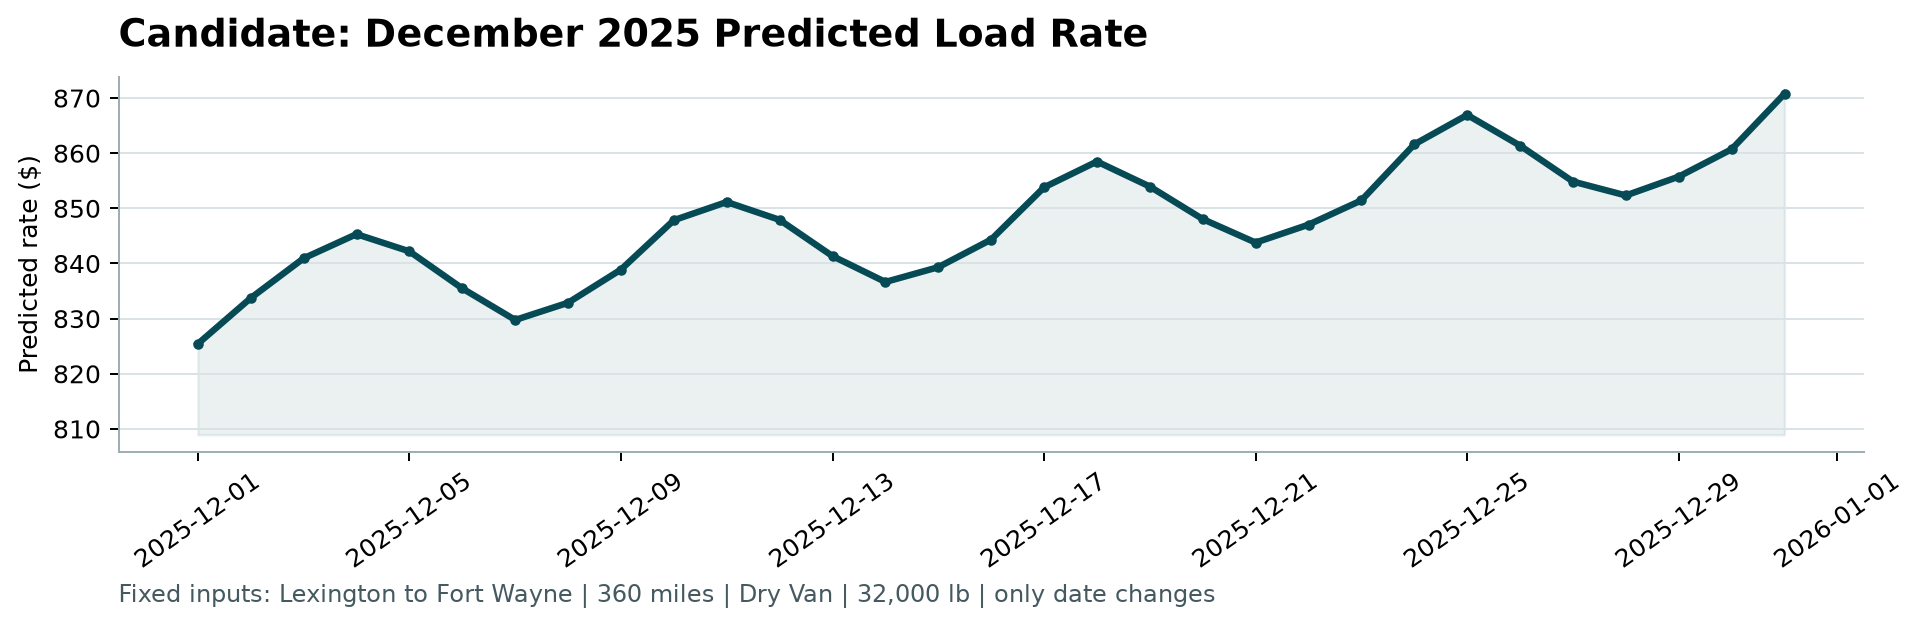

In [16]:
!"{sys.executable}" score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs.csv
from IPython.display import Image
Image('scorer_results/candidate_december.png')

The December line has the weekly cycle from market_index and rises into the quarter end, which is what sections 3-4 said it should do.

Things I can't check from this data: holiday effects (no Nov/Dec in training), and whether the trend keeps the same slope. The fold results have a bias of up to about +-0.9% in single months, so something similar could show up in validation.